# Practical 9: Density-Based Clustering with DBSCAN

**Subject:** Machine Learning  |  **Type:** Unsupervised learning, clustering

## Aim
Employ a **density-based clustering algorithm such as DBSCAN** using a suitable open-access dataset to identify the **clustering structure and noise points**.

## Datasets
- **Part A: make_moons** (two interleaved half-moons with some noise): shows DBSCAN finding arbitrary shapes and noise, where K-Means fails.
- **Part B: Iris** (real dataset): DBSCAN on real measurements.

## Key terms
| Term | Meaning |
|---|---|
| **eps (ε)** | Radius of the neighbourhood around a point |
| **min_samples** | Minimum number of points within eps for a point to count as dense |
| **Core point** | Has at least `min_samples` points (including itself) within eps |
| **Border point** | Within eps of a core point but not core itself |
| **Noise point** | Neither core nor border: label **-1** |

## Steps
1. Scale data, find eps with the k-distance plot
2. Fit DBSCAN, count clusters and noise
3. Classify points as core / border / noise
4. Compare with K-Means
5. Sensitivity to eps
6. Part B: Iris

## Step 0: Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_moons, load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, KMeans
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

sns.set_theme(style="whitegrid")

## Part A: Moons dataset

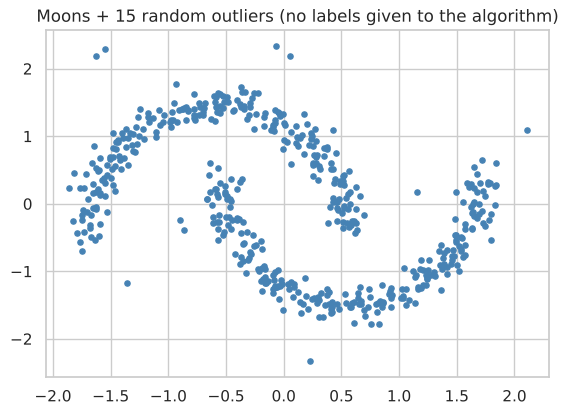

In [2]:
X, y_true = make_moons(n_samples=500, noise=0.07, random_state=42)
# add a few random outliers so that there are real noise points to find
rng = np.random.default_rng(1)
outliers = rng.uniform(low=[-1.5, -1.0], high=[2.5, 1.5], size=(15, 2))
X = np.vstack([X, outliers])
y_true = np.r_[y_true, -np.ones(15, dtype=int)]       # -1 = injected outlier
Xs = StandardScaler().fit_transform(X)

plt.figure(figsize=(6.5, 4.5))
plt.scatter(Xs[:, 0], Xs[:, 1], s=14, c="steelblue"); plt.title("Moons + 15 random outliers (no labels given to the algorithm)")
plt.show()

## Step 1: Choose eps with the k-distance plot

Rule of thumb: `min_samples` ≈ 2 × number of features (use 4 or 5 for 2-D data). For each point, compute the distance to its `min_samples`-th nearest neighbour, sort these distances and plot them. Points in dense areas have small distances; outliers have large distances. The **knee** (sharp bend) is a good eps.

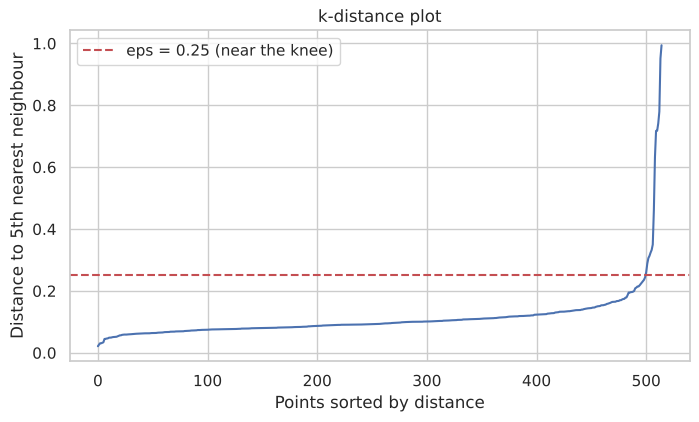

In [3]:
min_samples = 5
nn = NearestNeighbors(n_neighbors=min_samples).fit(Xs)
dist, _ = nn.kneighbors(Xs)
kdist = np.sort(dist[:, -1])

plt.figure(figsize=(8, 4.3))
plt.plot(kdist)
plt.axhline(0.25, color="r", ls="--", label="eps = 0.25 (near the knee)")
plt.xlabel("Points sorted by distance"); plt.ylabel(f"Distance to {min_samples}th nearest neighbour")
plt.title("k-distance plot"); plt.legend(); plt.show()

**How to read this:** the curve is almost flat for most points (dense regions) and then **rises sharply** at the right end (sparse points and outliers). The y-value where it bends upward, the **knee**, is the best eps: a distance that connects dense-region points but not the outliers. Here the knee is around 0.2 to 0.3.

## Step 2: Fit DBSCAN

In [4]:
db = DBSCAN(eps=0.25, min_samples=min_samples).fit(Xs)
labels = db.labels_
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = int((labels == -1).sum())
print("Estimated clusters:", n_clusters)
print("Noise points      :", n_noise, f"({n_noise / len(Xs):.1%})")
print("Points per cluster:", dict(zip(*np.unique(labels[labels != -1], return_counts=True))))

mask = labels != -1
if n_clusters > 1:
    print("Silhouette (non-noise points): %.3f" % silhouette_score(Xs[mask], labels[mask]))

Estimated clusters: 2
Noise points      : 10 (1.9%)
Points per cluster: {np.int64(0): np.int64(253), np.int64(1): np.int64(252)}
Silhouette (non-noise points): 0.386


## Step 3: Core, border and noise points

Core: 500 | Border: 5 | Noise: 10


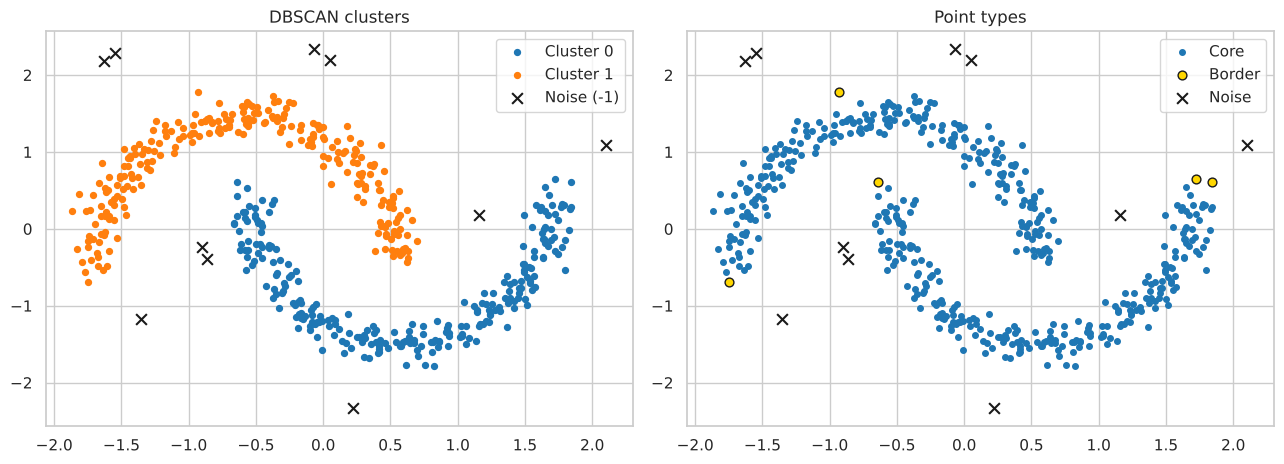

In [5]:
core_mask = np.zeros(len(Xs), dtype=bool)
core_mask[db.core_sample_indices_] = True
border_mask = (labels != -1) & ~core_mask
noise_mask = labels == -1
print("Core:", core_mask.sum(), "| Border:", border_mask.sum(), "| Noise:", noise_mask.sum())

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
palette = {0: "tab:blue", 1: "tab:orange", 2: "tab:green", 3: "tab:purple"}
for cl in sorted(set(labels) - {-1}):
    pts = labels == cl
    ax[0].scatter(Xs[pts, 0], Xs[pts, 1], s=18, color=palette.get(cl, "grey"), label=f"Cluster {cl}")
ax[0].scatter(Xs[noise_mask, 0], Xs[noise_mask, 1], c="k", marker="x", s=60, label="Noise (-1)")
ax[0].set_title("DBSCAN clusters"); ax[0].legend()

ax[1].scatter(Xs[core_mask, 0], Xs[core_mask, 1], s=16, c="tab:blue", label="Core")
ax[1].scatter(Xs[border_mask, 0], Xs[border_mask, 1], s=40, c="gold", edgecolor="k", label="Border")
ax[1].scatter(Xs[noise_mask, 0], Xs[noise_mask, 1], c="k", marker="x", s=60, label="Noise")
ax[1].set_title("Point types"); ax[1].legend()
plt.tight_layout(); plt.show()

**How to read these:**
- **Left:** each colour is a cluster and the **black crosses** are noise points (label -1): points in low-density regions that belong to no cluster. DBSCAN recovered the **two moons** (253 and 252 points) and flagged **10 points as noise**, without being told the number of clusters. We injected 15 random outliers, but only 10 were flagged: the other 5 landed close enough to a moon to be absorbed into it, which is correct behaviour for a density-based method (they are not isolated).
- **Right:** **core** points (blue) are in dense areas; **border** points (yellow) sit on the edge of a cluster, within eps of a core point but with too few neighbours of their own; **noise** is everything else.

## Step 4: DBSCAN vs K-Means

Adjusted Rand Index vs true moons (excluding injected outliers):
   K-Means: 0.445
   DBSCAN : 1.000


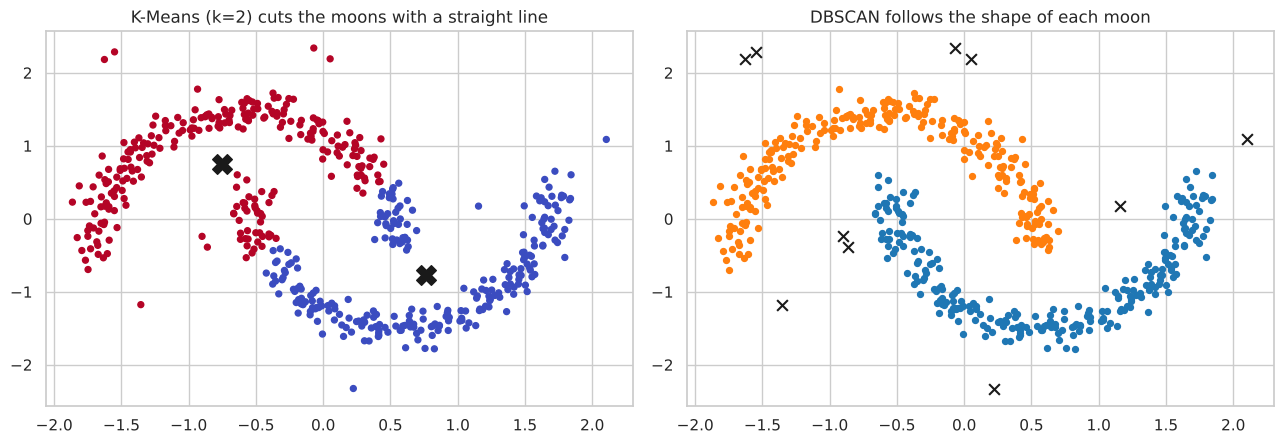

In [6]:
km = KMeans(n_clusters=2, n_init=10, random_state=0).fit(Xs)
true_mask = y_true != -1
print("Adjusted Rand Index vs true moons (excluding injected outliers):")
print("   K-Means: %.3f" % adjusted_rand_score(y_true[true_mask], km.labels_[true_mask]))
print("   DBSCAN : %.3f" % adjusted_rand_score(y_true[true_mask & mask], labels[true_mask & mask]))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
ax[0].scatter(Xs[:, 0], Xs[:, 1], c=km.labels_, cmap="coolwarm", s=18)
ax[0].scatter(*km.cluster_centers_.T, c="k", marker="X", s=200)
ax[0].set_title("K-Means (k=2) cuts the moons with a straight line")
for cl in sorted(set(labels) - {-1}):
    ax[1].scatter(Xs[labels == cl, 0], Xs[labels == cl, 1], s=18, color=palette.get(cl, "grey"))
ax[1].scatter(Xs[noise_mask, 0], Xs[noise_mask, 1], c="k", marker="x", s=60)
ax[1].set_title("DBSCAN follows the shape of each moon")
plt.tight_layout(); plt.show()

**How to read these:** K-Means assumes round clusters around a centre, so it splits the plane with a straight boundary and mixes the two moons. DBSCAN grows clusters through connected dense regions, so it follows the curved shape. The Adjusted Rand Index (1 = perfect match) quantifies this: DBSCAN scores far higher.

## Step 5: Sensitivity to eps

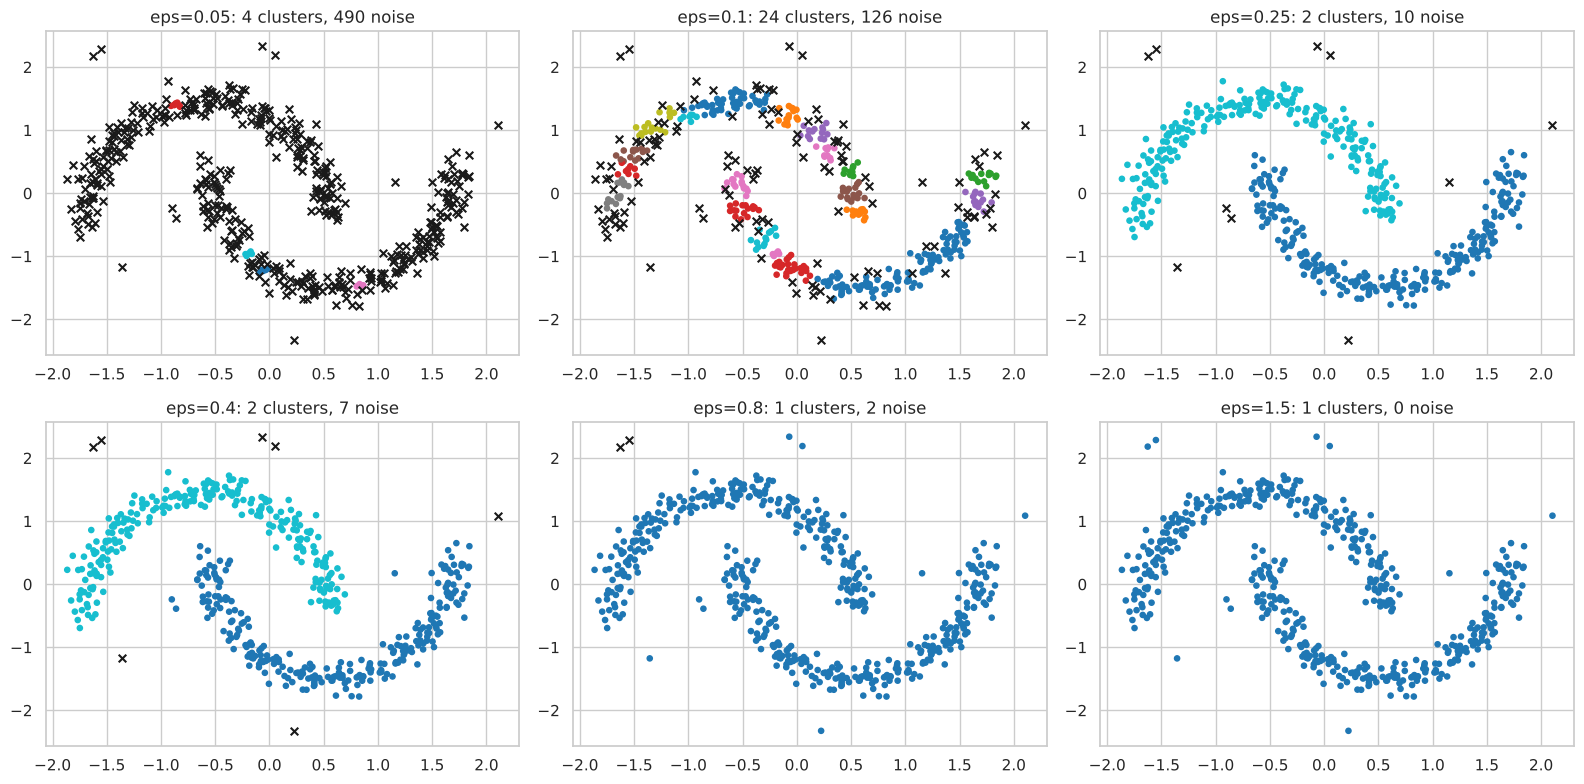

,eps,clusters,noise points
0,0.05,4,490
1,0.10,24,126
2,0.25,2,10
3,0.40,2,7
4,0.80,1,2
5,1.50,1,0


In [7]:
eps_list = [0.05, 0.1, 0.25, 0.4, 0.8, 1.5]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
summary = []
for ax, e in zip(axes.ravel(), eps_list):
    lab = DBSCAN(eps=e, min_samples=min_samples).fit_predict(Xs)
    ncl = len(set(lab)) - (1 if -1 in lab else 0)
    nn_ = int((lab == -1).sum())
    ax.scatter(Xs[lab != -1, 0], Xs[lab != -1, 1], c=lab[lab != -1], cmap="tab10", s=14)
    ax.scatter(Xs[lab == -1, 0], Xs[lab == -1, 1], c="k", marker="x", s=30)
    ax.set_title(f"eps={e}: {ncl} clusters, {nn_} noise")
    summary.append({"eps": e, "clusters": ncl, "noise points": nn_})
plt.tight_layout(); plt.show()
pd.DataFrame(summary)

**How to read this grid:** eps is the key parameter (numbers from my run).
- **Too small (0.05, 0.1):** almost nothing is dense enough, so most points become **noise** (490 of 515 at eps = 0.05) and many tiny clusters appear (24 clusters at eps = 0.1).
- **Just right (0.25 to 0.4):** exactly two clusters (the moons) plus 7 to 10 noise points.
- **Too large (0.8, 1.5):** neighbourhoods overlap, the two moons **merge into one cluster** and the outliers get absorbed, so noise drops to 2 and then 0.

## Part B: DBSCAN on Iris (real data)

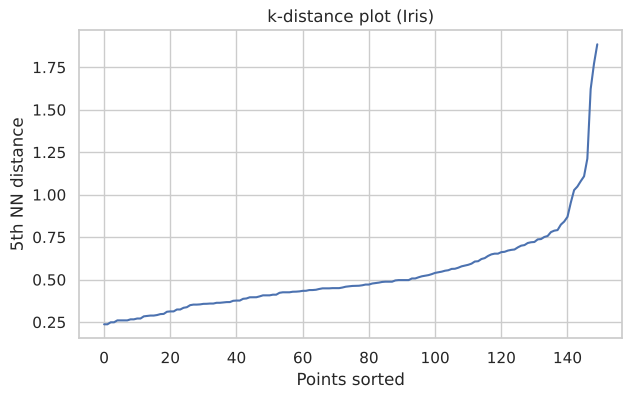

,eps,clusters,noise
0,0.3,3,120
1,0.4,6,66
2,0.5,2,34
3,0.6,2,26
4,0.8,2,4
5,1.0,2,3


In [8]:
iris = load_iris()
Xi = StandardScaler().fit_transform(iris.data)
yi = iris.target

ms = 5
d_i, _ = NearestNeighbors(n_neighbors=ms).fit(Xi).kneighbors(Xi)
plt.figure(figsize=(7, 4)); plt.plot(np.sort(d_i[:, -1])); plt.xlabel("Points sorted"); plt.ylabel("5th NN distance")
plt.title("k-distance plot (Iris)"); plt.show()

rows = []
for e in [0.3, 0.4, 0.5, 0.6, 0.8, 1.0]:
    lab = DBSCAN(eps=e, min_samples=ms).fit_predict(Xi)
    ncl = len(set(lab)) - (1 if -1 in lab else 0)
    rows.append({"eps": e, "clusters": ncl, "noise": int((lab == -1).sum())})
pd.DataFrame(rows)

Clusters: 2 | Noise: 26
DBSCAN label  -1   0   1
True species            
setosa         4  46   0
versicolor     8   0  42
virginica     14   0  36


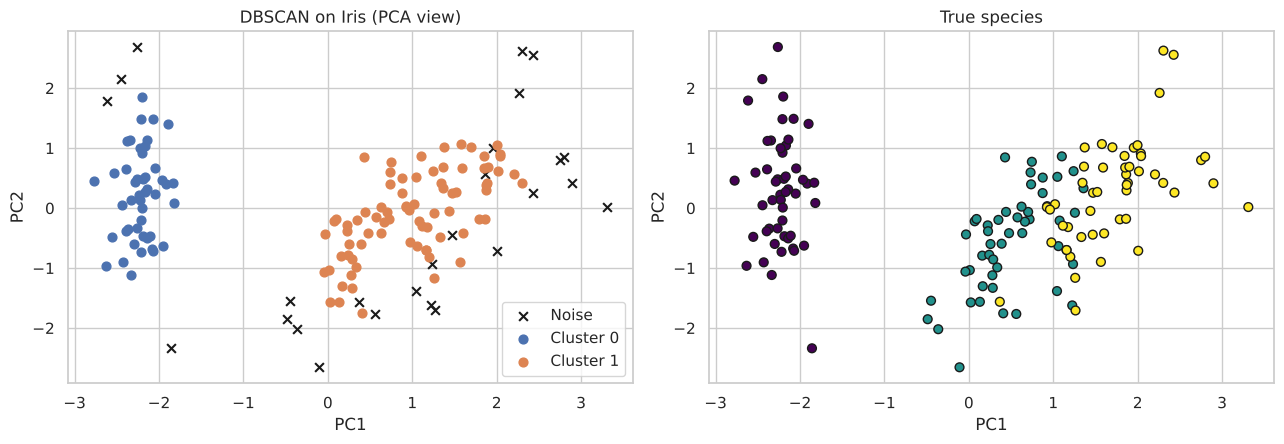

In [9]:
db_i = DBSCAN(eps=0.6, min_samples=ms).fit(Xi)
li = db_i.labels_
print("Clusters:", len(set(li)) - (1 if -1 in li else 0), "| Noise:", int((li == -1).sum()))
print(pd.crosstab(pd.Series(yi, name="True species").map(dict(enumerate(iris.target_names))), pd.Series(li, name="DBSCAN label")))

Xp = PCA(n_components=2).fit_transform(Xi)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
for cl in sorted(set(li)):
    pts = li == cl
    ax[0].scatter(Xp[pts, 0], Xp[pts, 1], label="Noise" if cl == -1 else f"Cluster {cl}",
                  marker="x" if cl == -1 else "o", c="k" if cl == -1 else None, s=40)
ax[0].legend(); ax[0].set_title("DBSCAN on Iris (PCA view)")
ax[1].scatter(Xp[:, 0], Xp[:, 1], c=yi, cmap="viridis", s=40, edgecolor="k"); ax[1].set_title("True species")
for a in ax: a.set_xlabel("PC1"); a.set_ylabel("PC2")
plt.tight_layout(); plt.show()

**How to read this:** with scaled Iris and eps = 0.6, DBSCAN finds **2 clusters**: setosa (46 flowers) and versicolor + virginica merged together (78 flowers; they touch and form one dense region), plus **26 noise points (17% of the data)**. That is a lot of noise: Iris has few points per region, so many flowers on the edges of the clusters do not have enough close neighbours. The table above also shows how sensitive the result is to eps: eps = 0.3 gives 3 clusters but 120 noise points, eps = 0.4 gives 6 small clusters, and eps = 0.8 to 1.0 gives 2 clusters with only 3 to 4 noise points. DBSCAN is not wrong: it follows density, and versicolor and virginica are not separated by a gap of low density. This is a known limitation: DBSCAN cannot split two touching clusters of similar density, whereas K-Means with k = 3 can (though it also makes mistakes in the overlap).

## Result / Conclusion
- DBSCAN found the cluster structure (two moons) and flagged outlier points as noise without being told the number of clusters, and clearly outperformed K-Means on non-spherical clusters.
- eps controls the result: too small gives mostly noise, too large merges clusters. The k-distance plot helps choose it.
- On Iris, DBSCAN separates setosa from the rest but cannot split the overlapping versicolor and virginica, and the result (clusters and amount of noise) changes a lot with eps.

---
# Viva Questions and Answers

## A. Concept questions

**Q1. What is DBSCAN?**
Density-Based Spatial Clustering of Applications with Noise. It groups points that are closely packed (high density) and marks points in low-density regions as noise.

**Q2. What are its two parameters?**
`eps`, the neighbourhood radius, and `min_samples`, the minimum number of points to form a dense region.

**Q3. Explain core, border and noise points.**
Core: at least `min_samples` points within eps. Border: within eps of a core point but not core itself. Noise: neither.

**Q4. Explain the algorithm.**
Pick an unvisited point. If it is a core point, start a new cluster and add all density-reachable points, expanding through other core points. If it is not core, mark it as noise (it may later turn out to be a border point). Repeat until all points are visited.

**Q5. What is density-reachable and density-connected?**
A point q is density-reachable from p if there is a chain of core points from p to q, each within eps of the next. Two points are density-connected if both are reachable from a common core point.

**Q6. DBSCAN vs K-Means?**
DBSCAN needs no number of clusters, finds arbitrary shapes, detects noise, but is sensitive to eps and struggles with varying densities. K-Means needs k, finds only spherical clusters, assigns every point to a cluster (no noise concept) and is faster on large data.

**Q7. How do you choose eps and min_samples?**
`min_samples` is about 2 × the number of dimensions (at least 3 to 5). eps comes from the knee of the k-distance plot.

**Q8. Is DBSCAN sensitive to scaling?**
Yes, it is distance-based, so scale the features first.

**Q9. What are the drawbacks of DBSCAN?**
Hard to choose eps; fails when clusters have very different densities (one eps cannot fit all); poor in high dimensions (distances lose meaning); border points can be assigned differently depending on the processing order.

**Q10. What does label -1 mean?**
Noise (an outlier).

**Q11. Can DBSCAN be used for anomaly detection?**
Yes, the noise points are candidate anomalies.

**Q12. What distance metric does it use?**
Euclidean by default; others (Manhattan, cosine) can be set with `metric=`.

**Q13. Time complexity?**
$O(n\log n)$ with a spatial index such as a KD-tree, $O(n^2)$ without.

**Q14. What is HDBSCAN?**
An extension that removes the need for eps and handles clusters of varying density.

**Q15. How do you evaluate DBSCAN?**
Silhouette score on non-noise points, Davies-Bouldin index, or Adjusted Rand Index if true labels exist; also report the noise percentage.

**Q16. Does DBSCAN need the number of clusters in advance?**
No. The number of clusters is a result.

**Q17. Is DBSCAN deterministic?**
Core points and noise are deterministic; border points reachable from two clusters may be assigned to either, depending on order.

**Q18. What happens if eps is too small? Too large?**
Too small: most points become noise and many tiny clusters appear. Too large: clusters merge into one.

**Q19. What happens if `min_samples` is increased?**
A denser region is required, so more points become noise and small clusters disappear; the result is more conservative.

**Q20. Why did DBSCAN not separate versicolor and virginica in Iris?**
They overlap and form one continuous dense region, so there is no low-density gap for DBSCAN to cut along.

**Q21. Can DBSCAN find clusters of different shapes?**
Yes, any shape (even non-convex ones like moons, rings and spirals).

## B. Questions about the graphs

**G1. How do you read the k-distance plot?**
Each point's distance to its k-th nearest neighbour is sorted ascending. The curve is flat for dense-region points and rises sharply for sparse points and outliers. The y-value at the knee is the best eps.

**G2. What do the black crosses mean in the cluster plot?**
Noise points (label -1): points in low-density regions that belong to no cluster.

**G3. Why does DBSCAN beat K-Means on the moons?**
DBSCAN follows dense regions and forms arbitrarily shaped clusters; K-Means assumes round clusters around centroids, so it splits the moons with a straight boundary.

**G4. How many clusters did DBSCAN find and how do you know?**
Count the unique labels excluding -1. The number of clusters comes from the data, not from the user.

**G5. What does the eps sensitivity grid show?**
Tiny eps gives mostly noise and many clusters; the right eps gives the true structure; a large eps merges everything into one cluster with no noise.

**G6. What do the core, border and noise colours mean?**
Core (blue): dense interior points. Border (yellow): on the edge of a cluster. Noise (black x): outliers.

**G7. What does the Iris result tell you about DBSCAN?**
It finds setosa as one cluster and merges versicolor and virginica, because density does not separate them.

## C. Code questions

**C1. What does `db.labels_` contain?**
The cluster index of each point; -1 means noise.

**C2. What does `db.core_sample_indices_` contain?**
Indices of the core points.

**C3. Why add random outliers in Part A?**
To have genuine noise points to detect, which demonstrates DBSCAN's outlier handling.

**C4. Why `NearestNeighbors(n_neighbors=min_samples)`?**
To get each point's distance to its min_samples-th neighbour for the k-distance plot.